# Data Exploration Stage 1: Data Forensics & Quality Audit

Now we will cover the first stage of the data exploration plan for the BRSET dataset, focusing on:
1.  **Metadata Preprocessing**: Parsing labels for Hypertension detection.
2.  **Physical Audit**: Checking image resolution consistency.
3.  **Quality Metrics**: Calculating Fill Factor (Black Borders), Green Channel Variance, and Blur Score.

**Goal**: Ensure the physical integrity of the images before proceeding to leakage checks.

In [21]:
import pandas as pd
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# Set paths
BASE_DIR = r"D:\PhysioNetData\physionet.org\files\brazilian-ophthalmological\1.0.1"
IMG_DIR = os.path.join(BASE_DIR, "fundus_photos") 
CSV_PATH = os.path.join(BASE_DIR, "labels_brset.csv")

print(f"Image Directory: {IMG_DIR}")
print(f"Labels File: {CSV_PATH}")

Image Directory: D:\PhysioNetData\physionet.org\files\brazilian-ophthalmological\1.0.1\fundus_photos
Labels File: D:\PhysioNetData\physionet.org\files\brazilian-ophthalmological\1.0.1\labels_brset.csv


In [22]:
# Load Data & Parse Labels
df = pd.read_csv(CSV_PATH)

def parse_hypertension(comorbidities):
    if pd.isna(comorbidities):
        return 0
    # Check for 'hypertension' (case insensitive)
    if 'hypertension' in str(comorbidities).lower():
        return 1
    return 0

df['label'] = df['comorbidities'].apply(parse_hypertension)
df['label_str'] = df['label'].map({0: 'Normal', 1: 'Hypertension'})

print(f"Total Samples: {len(df)}")
print("Class Distribution:")
print(df['label_str'].value_counts())

# Add full image path
df['filepath'] = df['image_id'].apply(lambda x: os.path.join(IMG_DIR, x + ".jpg")) 
# Check if first file exists
print(f"First file exists: {os.path.exists(df.iloc[0]['filepath'])}")
df.head()

Total Samples: 16266
Class Distribution:
label_str
Normal          12946
Hypertension     3320
Name: count, dtype: int64
First file exists: True


,image_id,patient_id,camera,patient_age,comorbidities,diabetes_time_y,insuline,patient_sex,exam_eye,diabetes,...,drusens,hemorrhage,retinal_detachment,myopic_fundus,increased_cup_disc,other,quality,label,label_str,filepath
0,img00001,1,Canon CR,48.0,diabetes1,12,yes,1,1,yes,...,0,0,0,0,1,0,Adequate,0,Normal,D:\PhysioNetData\physionet.org\files\brazilian...
1,img00002,1,Canon CR,48.0,diabetes1,12,yes,1,2,yes,...,0,0,0,0,1,0,Adequate,0,Normal,D:\PhysioNetData\physionet.org\files\brazilian...
2,img00003,2,Canon CR,18.0,diabetes1,7,yes,2,1,yes,...,0,0,0,0,0,0,Adequate,0,Normal,D:\PhysioNetData\physionet.org\files\brazilian...
3,img00004,2,Canon CR,18.0,diabetes1,7,yes,2,2,yes,...,0,0,0,0,0,0,Adequate,0,Normal,D:\PhysioNetData\physionet.org\files\brazilian...
4,img00005,3,Canon CR,22.0,diabetes1,11,yes,1,1,yes,...,0,0,0,0,0,0,Adequate,0,Normal,D:\PhysioNetData\physionet.org\files\brazilian...


In [23]:
# Stage 1: Physical Audit Loop
# Calculating Resolution, Fill Factor, Green Channel Variance, and Blur Score

widths = []
heights = []
fill_factors = []
green_vars = []
blur_scores = []

# Process images
# Using a subset for demonstration/speed if needed, but intended for full dataset audit
for idx, row in tqdm(df.iterrows(), total=len(df), desc="Auditing Images"):
    filepath = row['filepath']
    
    if not os.path.exists(filepath):
        # Handle missing file case
        widths.append(np.nan)
        heights.append(np.nan)
        fill_factors.append(np.nan)
        green_vars.append(np.nan)
        blur_scores.append(np.nan)
        continue

    img = cv2.imread(filepath)
    if img is None:
        widths.append(np.nan); heights.append(np.nan); fill_factors.append(np.nan)
        green_vars.append(np.nan); blur_scores.append(np.nan)
        continue

    # 1. Resolution Check
    h, w, _ = img.shape
    widths.append(w)
    heights.append(h)

    # 2. Black Border Analysis (Fill Factor)
    # Convert to grayscale and threshold to separate tissue from black background
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # Threshold > 10 usually separates fundus from back background
    tissue_pixels = np.count_nonzero(gray > 10)
    total_pixels = h * w
    fill_factors.append(tissue_pixels / total_pixels)

    # 3. Green Channel Variance (Quality/Content Check)
    # Green channel usually has best contrast for vessels
    green_channel = img[:, :, 1]
    green_vars.append(np.std(green_channel))

    # 4. Blur Score (Laplacian Variance)
    laplacian_var = cv2.Laplacian(gray, cv2.CV_64F).var()
    blur_scores.append(laplacian_var)

# Add metrics to DataFrame
df['width'] = widths
df['height'] = heights
df['fill_factor'] = fill_factors
df['green_std'] = green_vars
df['blur_score'] = blur_scores

# Drop rows with missing images for analysis
df_audit = df.dropna(subset=['width'])
print(f"Successfully audited {len(df_audit)} images.")

Auditing Images: 100%|██████████| 16266/16266 [49:11<00:00,  5.51it/s] 


Successfully audited 16239 images.


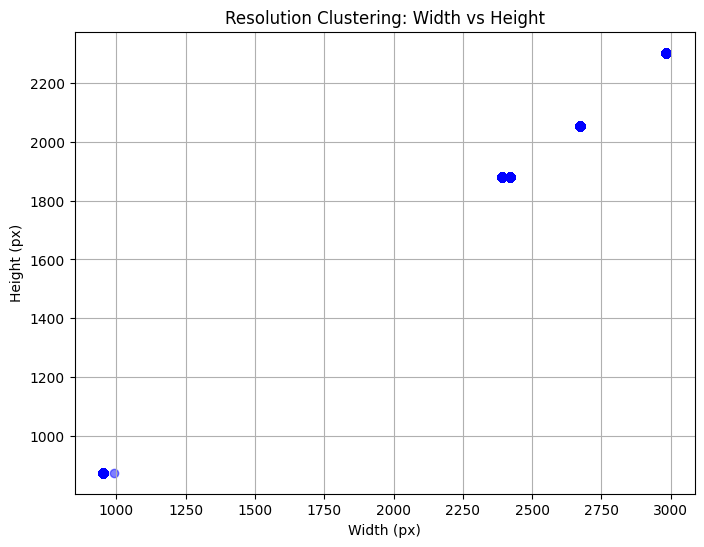

Resolution Counts:
    width  height  count
4  2672.0  2056.0   5579
5  2984.0  2304.0   4923
2  2390.0  1880.0   3640
3  2420.0  1880.0   1693
0   951.0   874.0    403


In [24]:
# Visualizing Resolution Clusters
plt.figure(figsize=(8, 6))
plt.scatter(df_audit['width'], df_audit['height'], alpha=0.5, c='blue')
plt.title("Resolution Clustering: Width vs Height")
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.grid(True)
plt.show()

print("Resolution Counts:")
print(df_audit.groupby(['width', 'height']).size().reset_index(name='count').sort_values('count', ascending=False).head())

C:\Users\msii\AppData\Local\Temp\ipykernel_39460\2376052077.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_audit, x='label_str', y='fill_factor', ax=axes[0], palette={'Normal':'green', 'Hypertension':'red'})
C:\Users\msii\AppData\Local\Temp\ipykernel_39460\2376052077.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_audit, x='label_str', y='green_std', ax=axes[1], palette={'Normal':'green', 'Hypertension':'red'})
C:\Users\msii\AppData\Local\Temp\ipykernel_39460\2376052077.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.bo

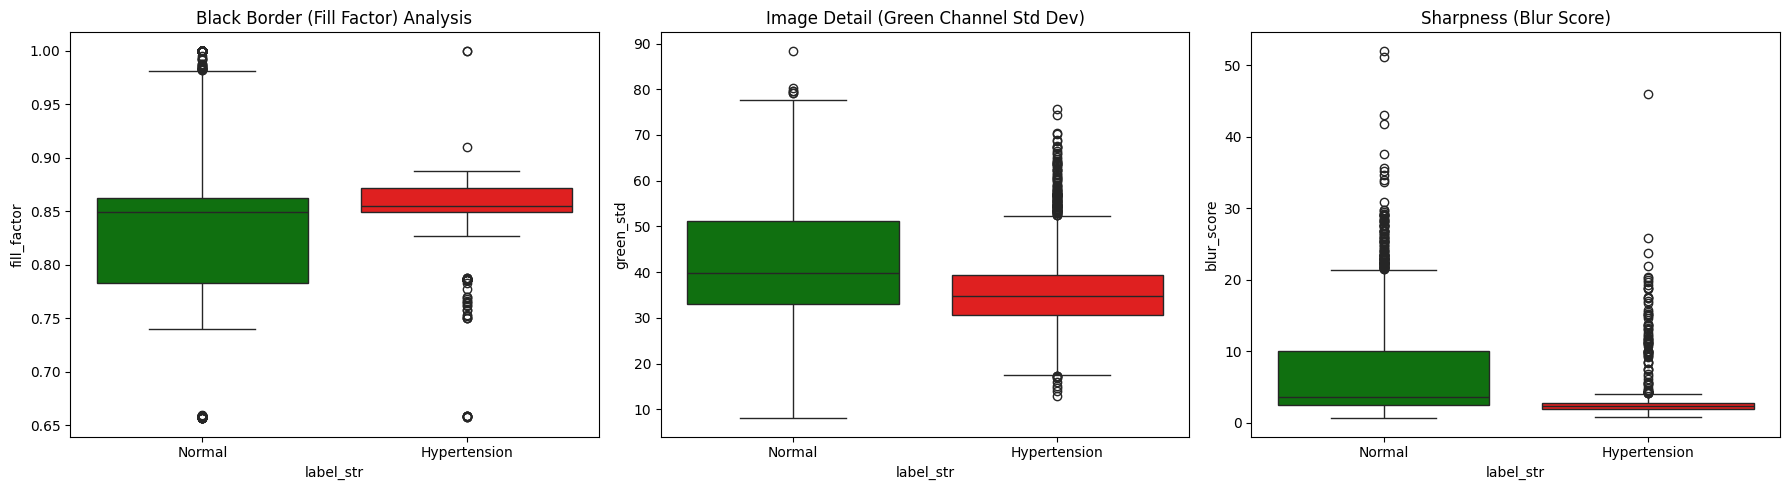

In [25]:
# Visualizing Quality Metrics Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Fill Factor
sns.boxplot(data=df_audit, x='label_str', y='fill_factor', ax=axes[0], palette={'Normal':'green', 'Hypertension':'red'})
axes[0].set_title("Black Border (Fill Factor) Analysis")

# Green Channel Variance
sns.boxplot(data=df_audit, x='label_str', y='green_std', ax=axes[1], palette={'Normal':'green', 'Hypertension':'red'})
axes[1].set_title("Image Detail (Green Channel Std Dev)")

# Blur Score
sns.boxplot(data=df_audit, x='label_str', y='blur_score', ax=axes[2], palette={'Normal':'green', 'Hypertension':'red'})
axes[2].set_title("Sharpness (Blur Score)")

plt.tight_layout()
plt.show()

In [26]:
# Save logical checks summary
print("Quality Logic Checks:")
print(f"Images with Fill Factor < 0.35 (Potential Bad Crop): {len(df_audit[df_audit['fill_factor'] < 0.35])}")
print(f"Images with Green Std < 15 (Potential Washout/Blur): {len(df_audit[df_audit['green_std'] < 15])}")

Quality Logic Checks:
Images with Fill Factor < 0.35 (Potential Bad Crop): 0
Images with Green Std < 15 (Potential Washout/Blur): 36


Top 3 Most Blurred Images:


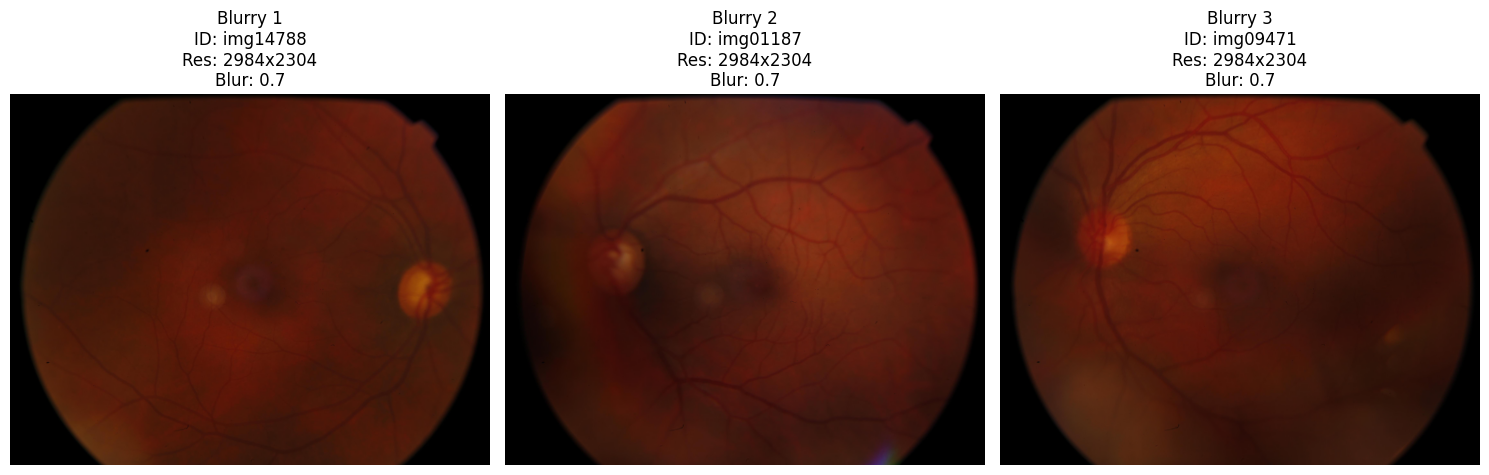

Top 3 Smallest Images:


C:\Users\msii\AppData\Local\Temp\ipykernel_39460\3814492521.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_audit['area'] = df_audit['width'] * df_audit['height']


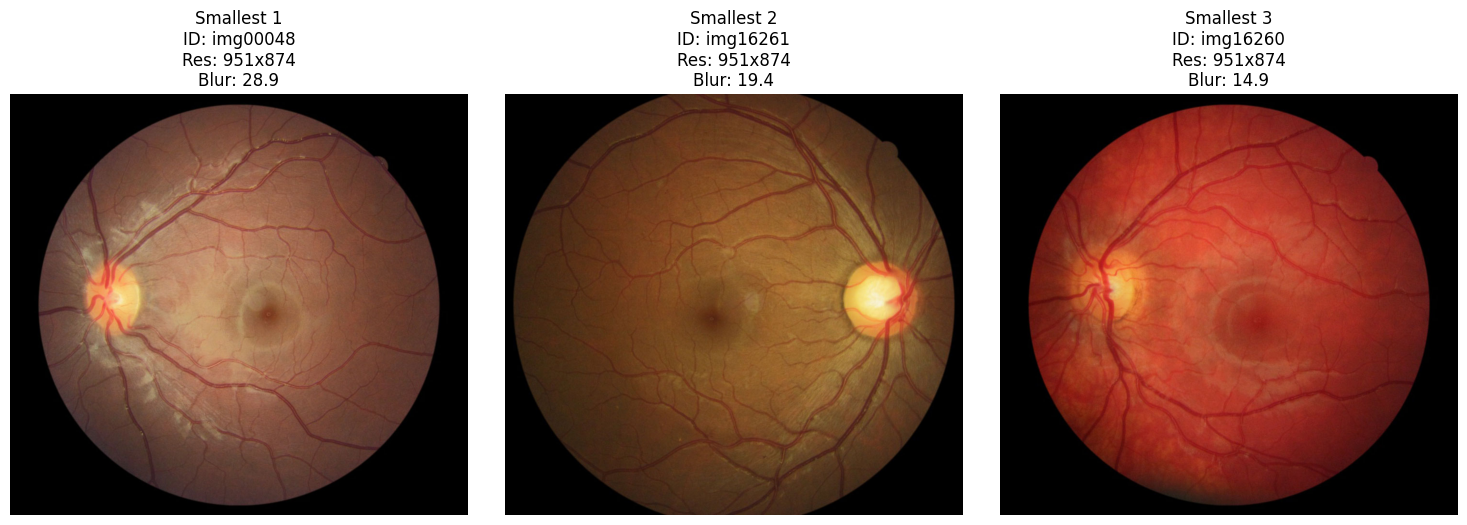

Top 3 Biggest Images:


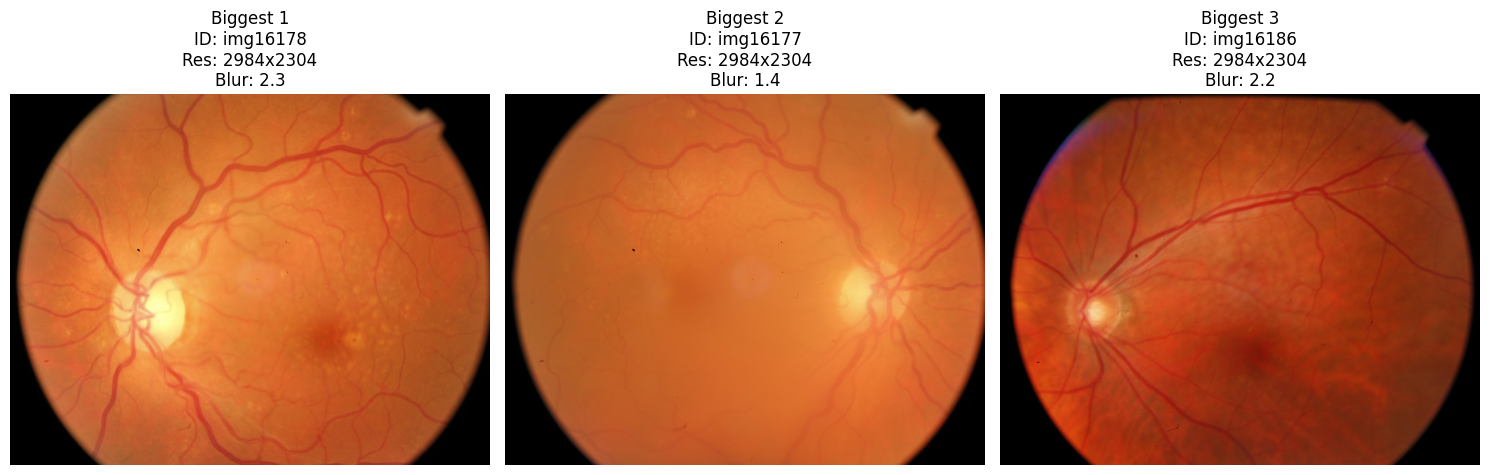

In [27]:
# Visualizing Data Extremes & Potential Issues

def show_samples(df, indices, title_prefix, cols=3):
    plt.figure(figsize=(15, 5))
    for i, idx in enumerate(indices[:cols]):
        row = df.loc[idx]
        filepath = row['filepath']
        if os.path.exists(filepath):
            img = cv2.imread(filepath)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.subplot(1, cols, i+1)
            plt.imshow(img)
            # Show key metrics in title
            plt.title(f"{title_prefix} {i+1}\nID: {row['image_id']}\nRes: {int(row['width'])}x{int(row['height'])}\nBlur: {row['blur_score']:.1f}")
            plt.axis('off')
    plt.tight_layout()
    plt.show()

# 1. Most Blurred Images (Lowest Blur Score)
print("Top 3 Most Blurred Images:")
blur_indices = df_audit.sort_values('blur_score').head(3).index
show_samples(df_audit, blur_indices, "Blurry")

# 2. Smallest Images (Lowest Resolution Area)
print("Top 3 Smallest Images:")
df_audit['area'] = df_audit['width'] * df_audit['height']
small_indices = df_audit.sort_values('area').head(3).index
show_samples(df_audit, small_indices, "Smallest")

# 3. Biggest Images (Highest Resolution Area)
print("Top 3 Biggest Images:")
big_indices = df_audit.sort_values('area', ascending=False).head(3).index
show_samples(df_audit, big_indices, "Biggest")

Top 3 Most Blurred Images:


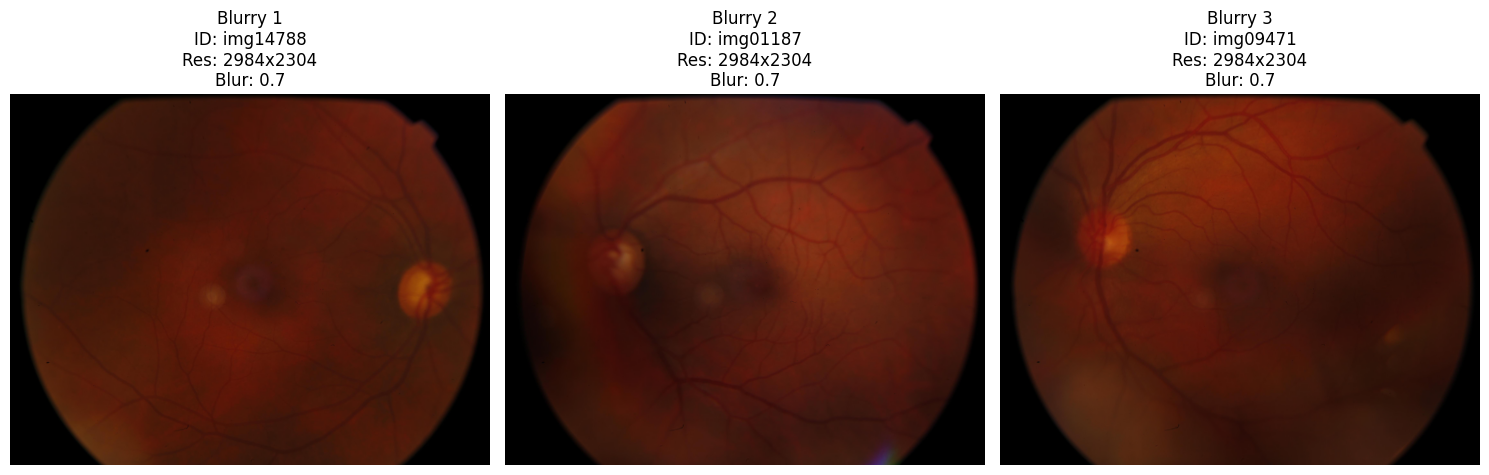

Top 3 Smallest Images:


C:\Users\msii\AppData\Local\Temp\ipykernel_39460\3413571785.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_audit['area'] = df_audit['width'] * df_audit['height']


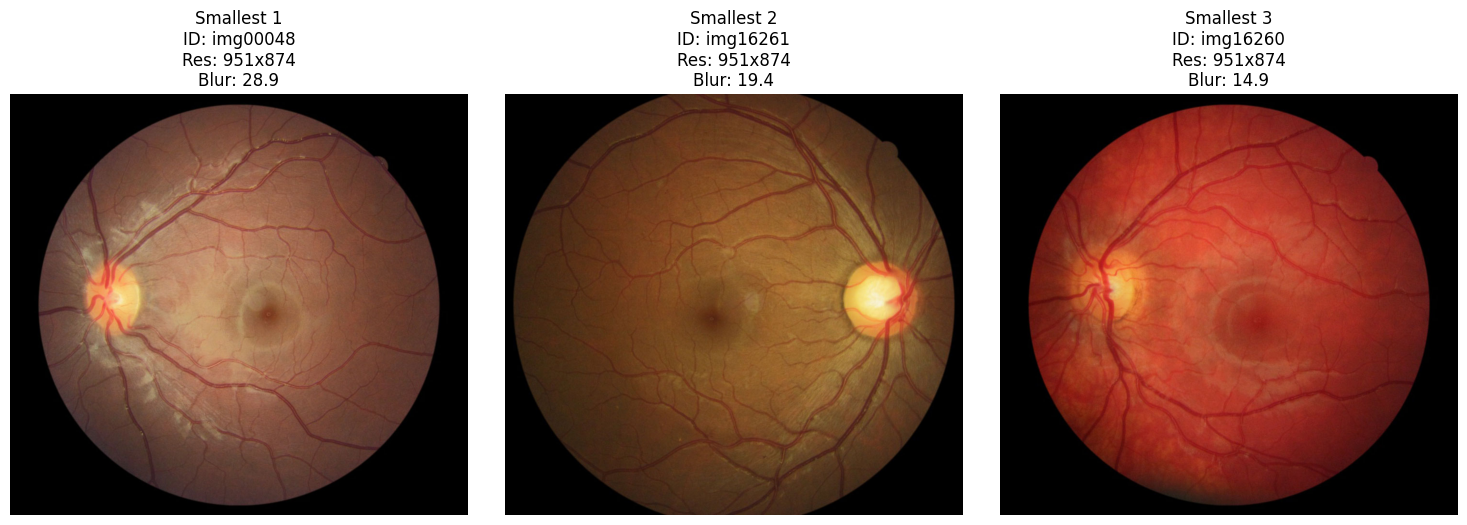

Top 3 Biggest Images:


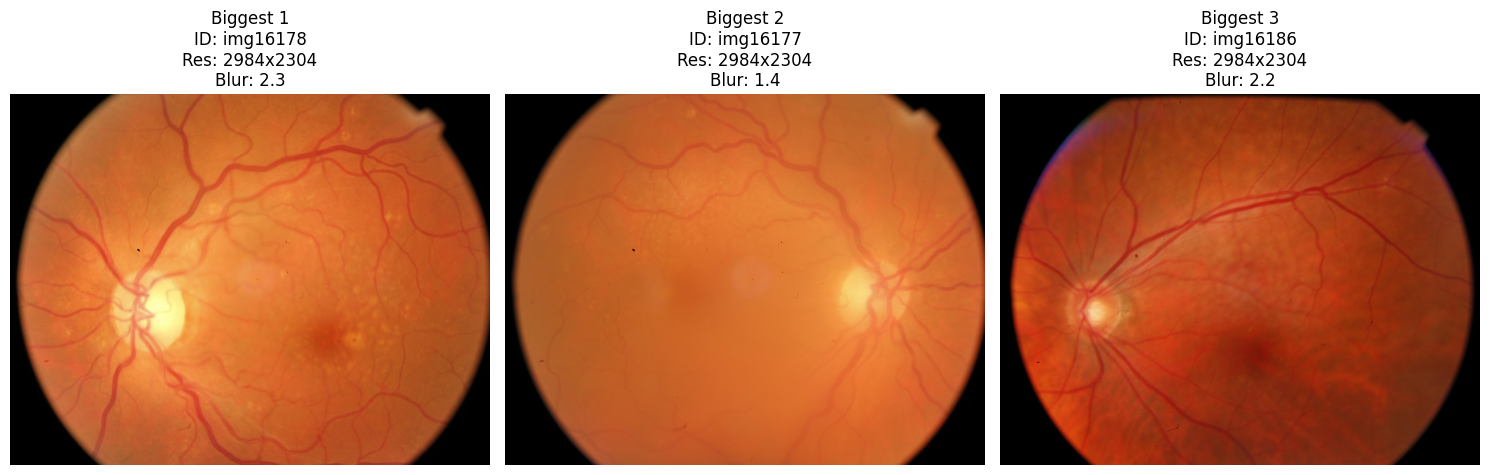


Total Images in Dataset: 16266
Successfully Audited: 16239
Unaudited/Missing Images (27):
['img00994', 'img01995', 'img02454', 'img02455', 'img02456', 'img02457', 'img02458', 'img02459', 'img02460', 'img02461', 'img02462', 'img02996', 'img03997', 'img04998', 'img05999', 'img07000', 'img08001', 'img08483', 'img08484', 'img09002', 'img10003', 'img11004', 'img12005', 'img13006', 'img14007', 'img15008', 'img16009']


In [28]:
# Visualizing Data Extremes & Potential Issues
import os
import cv2
import matplotlib.pyplot as plt

def show_samples(df, indices, title_prefix, cols=3):
    plt.figure(figsize=(15, 5))
    for i, idx in enumerate(indices[:cols]):
        row = df.loc[idx]
        filepath = row['filepath']
        if os.path.exists(filepath):
            img = cv2.imread(filepath)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.subplot(1, cols, i+1)
            plt.imshow(img)
            # Show key metrics in title
            plt.title(f"{title_prefix} {i+1}\nID: {row['image_id']}\nRes: {int(row['width'])}x{int(row['height'])}\nBlur: {row['blur_score']:.1f}")
            plt.axis('off')
    plt.tight_layout()
    plt.show()

# 1. Most Blurred Images (Lowest Blur Score)
if 'blur_score' in df_audit.columns:
    print("Top 3 Most Blurred Images:")
    blur_indices = df_audit.sort_values('blur_score').head(3).index
    show_samples(df_audit, blur_indices, "Blurry")

# 2. Smallest Images (Lowest Resolution Area)
print("Top 3 Smallest Images:")
df_audit['area'] = df_audit['width'] * df_audit['height']
small_indices = df_audit.sort_values('area').head(3).index
show_samples(df_audit, small_indices, "Smallest")

# 3. Biggest Images (Highest Resolution Area)
print("Top 3 Biggest Images:")
big_indices = df_audit.sort_values('area', ascending=False).head(3).index
show_samples(df_audit, big_indices, "Biggest")

# 4. Identify and Print Missing/Unaudited Images
missing_mask = df['width'].isna()
missing_images = df[missing_mask]['image_id'].tolist()
print(f"\nTotal Images in Dataset: {len(df)}")
print(f"Successfully Audited: {len(df_audit)}")
print(f"Unaudited/Missing Images ({len(missing_images)}):")
print(missing_images)

# Data Exploration Stage 2: Leakage Prevention

Now we will check for any potential leakage in the dataset.

In [29]:
# Stage 2: Leakage Prevention & Data Integrity
# ---------------------------------------------------------

import pandas as pd
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# 1. Patient-Level Isolation Check
print("--- 1. Patient-Level Isolation Check ---")
patient_ids = df['patient_id'].unique()
img_ids = df['image_id'].unique()

print(f"Total Unique Patients: {len(patient_ids)}")
print(f"Total Images: {len(img_ids)}")
print(f"Average Images per Patient: {len(img_ids)/len(patient_ids):.2f}")

# Simulation of Train/Test Split

train_pids, test_pids = train_test_split(patient_ids, test_size=0.2, random_state=42)
train_df = df[df['patient_id'].isin(train_pids)]
test_df = df[df['patient_id'].isin(test_pids)]

print(f"Overlap in Patient-Level Split: {len(set(train_df['patient_id']).intersection(set(test_df['patient_id'])))} patients")




--- 1. Patient-Level Isolation Check ---
Total Unique Patients: 8524
Total Images: 16266
Average Images per Patient: 1.91
Overlap in Patient-Level Split: 0 patients



--- 2. Artifact Scanning (Average Image by Eye Side) ---
Computing Normal Averages...
Computing average for Normal - All (12946 images)...


Normal-All:   0%|          | 0/12946 [00:00<?, ?it/s]

Computing average for Normal - Right (OD) (6480 images)...


Computing average for Normal - Left (OS) (6466 images)...


Computing Hypertension Averages...
Computing average for Hypertension - All (3320 images)...


Computing average for Hypertension - Right (OD) (1675 images)...


Computing average for Hypertension - Left (OS) (1645 images)...


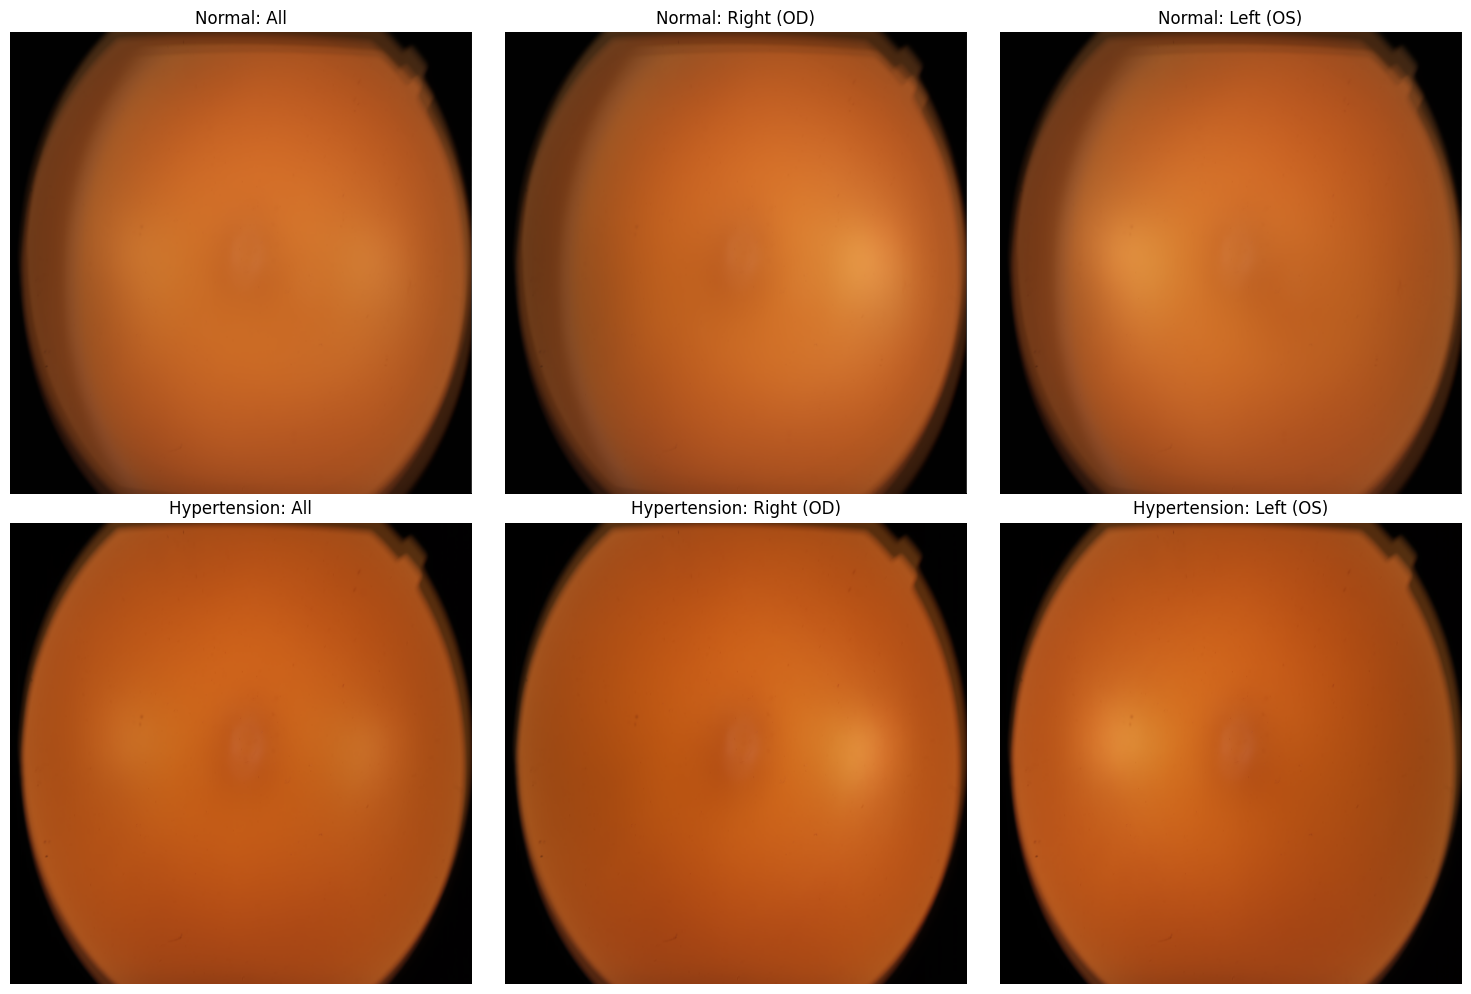

In [40]:
# 2. Artifact Scanning (Average Image) - SPLIT BY EYE
print("\n--- 2. Artifact Scanning (Average Image by Eye Side) ---")

def compute_average_image_split(df_subset, label_name, limit=17000):
    # Split by eye (Assuming 1=Right/OD, 2=Left/OS based on typical datasets)
    # We will verify if 1/2 exists.
    
    subsets = {
        "All": df_subset,
        "Right (OD)": df_subset[df_subset['exam_eye'] == 1],
        "Left (OS)": df_subset[df_subset['exam_eye'] == 2]
    }
    
    results = {}
    
    for side, sub_df in subsets.items():
        if len(sub_df) == 0:
            results[side] = None
            continue
            
        # Sample
        if len(sub_df) > limit:
            sub_df = sub_df.sample(limit, random_state=42)
            
        avg_img = None
        count = 0
        
        print(f"Computing average for {label_name} - {side} ({len(sub_df)} images)...")
        for idx, row in tqdm(sub_df.iterrows(), total=len(sub_df), desc=f"{label_name}-{side}", leave=False):
            filepath = row['filepath']
            if os.path.exists(filepath):
                try:
                    img = cv2.imread(filepath)
                    if img is not None:
                        img = cv2.resize(img, (512, 512))
                        if avg_img is None:
                            avg_img = np.float32(img)
                        else:
                            cv2.accumulate(img, avg_img)
                        count += 1
                except Exception:
                    pass
        
        if count > 0:
            results[side] = cv2.convertScaleAbs(avg_img / count)
        else:
            results[side] = None
            
    return results

# Compute Group Averages (using integer labels)
print("Computing Normal Averages...")
avgs_normal = compute_average_image_split(df[df['label']==0], "Normal")

print("Computing Hypertension Averages...")
avgs_hyper = compute_average_image_split(df[df['label']==1], "Hypertension")

# Visualize (2 Rows x 3 Columns)
plt.figure(figsize=(15, 10))

# Row 1: Normal
titles = ["All", "Right (OD)", "Left (OS)"]
for i, side in enumerate(titles):
    img = avgs_normal[side]
    plt.subplot(2, 3, i+1)
    if img is not None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"Normal: {side}")
    else:
        plt.text(0.5, 0.5, "No Data", ha='center')
        plt.title(f"Normal: {side}")
    plt.axis('off')

# Row 2: Hypertension
for i, side in enumerate(titles):
    img = avgs_hyper[side]
    plt.subplot(2, 3, i+4)
    if img is not None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"Hypertension: {side}")
    else:
        plt.text(0.5, 0.5, "No Data", ha='center')
        plt.title(f"Hypertension: {side}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [41]:
# 3. Laterality Check (Heuristic)
print("\n--- 3. Laterality Check (Optic Disc Position) ---")
# Simple heuristic: Optic disc is usually the brightest spot. 
# Check if max brightness x-coord aligns with exam_eye (1=Right, 2=Left - need to verify schema mapping)
# Usually OD is nasal. For Right Eye (OD on Right in image?), Left Eye (OD on Left?)
# Let's just visualize a few mismatches if any to calibrate.

def check_laterality(row):
    filepath = row['filepath']
    if not os.path.exists(filepath): return np.nan
    
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if img is None: return np.nan
    
    # Simple brightness centroid or max point
    minVal, maxVal, minLoc, maxLoc = cv2.minMaxLoc(img)
    x_max = maxLoc[0]
    width = img.shape[1]
    
    # Heuristic: 
    # If x_max > width/2 -> Right side of image
    # If x_max < width/2 -> Left side of image
    return "Right" if x_max > width/2 else "Left"

# Test on a small batch
sample_lat = df.sample(20, random_state=42).copy()
sample_lat['pred_side'] = sample_lat.apply(check_laterality, axis=1)

print("Laterality Check Sample:")
print(sample_lat[['image_id', 'exam_eye', 'pred_side']].head(10))
# Note: Interpreting 'exam_eye' (1/2) requires dataset docs. 
# 1 usually OD (Right), 2 usually OS (Left).


--- 3. Laterality Check (Optic Disc Position) ---
Laterality Check Sample:
       image_id  exam_eye pred_side
387    img00388         1     Right
1261   img01262         1     Right
2546   img02547         2      Left
284    img00285         1     Right
7198   img07199         1     Right
7277   img07278         2      Left
2467   img02468         1     Right
6275   img06276         2      Left
12128  img12129         2      Left
8499   img08500         2      Left


# Stage 3

In [48]:
# Stage 3: Clinical & Demographic Analysis (Bias Check) - FIXED
# ----------------------------------------------------------------
from scipy.stats import mannwhitneyu, chi2_contingency
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare Data for Statistical Analysis
print("--- Preparing Data ---")
# Ensure numeric columns are actually numeric
numeric_cols = ['patient_age', 'diabetes_time_y']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Map integer labels to strings for visualization (Fixes ValueError)
df['label_str'] = df['label'].map({0: 'Normal', 1: 'Hypertension'})



--- Preparing Data ---



--- 3.1 Age Distribution Analysis ---


C:\Users\msii\AppData\Local\Temp\ipykernel_39460\417946936.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_str', y='patient_age', data=df, palette={'Normal':'green', 'Hypertension':'red'})


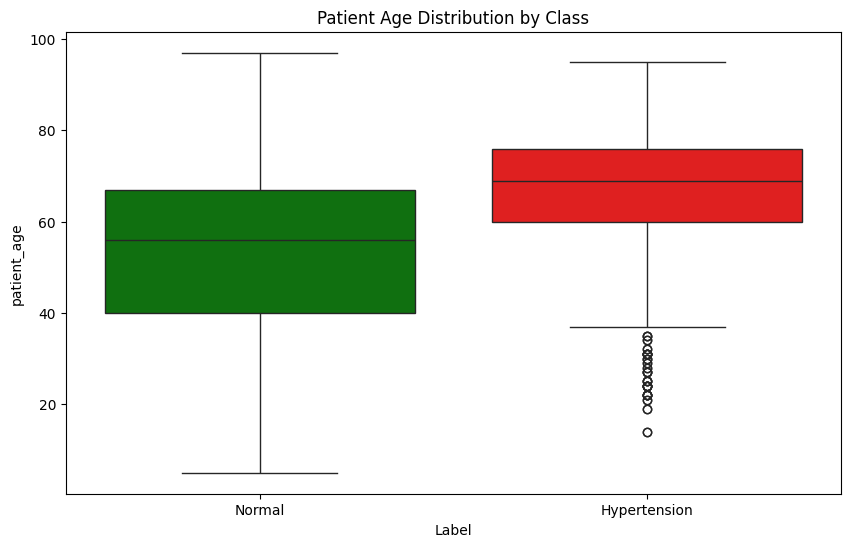

Age Comparison (Mann-Whitney U): p-value = 0.0000e+00

--- 3.2 Sex Distribution Analysis ---


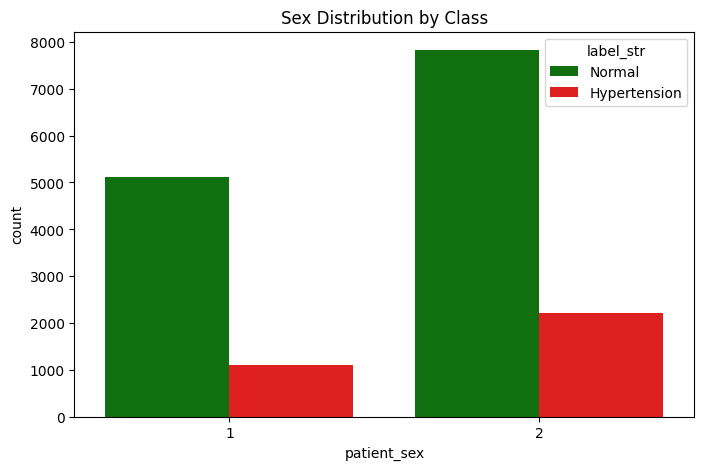

Sex Comparison (Chi-Square): p-value = 1.0519e-11


In [49]:
# 3.1 Age Distribution Analysis
print("\n--- 3.1 Age Distribution Analysis ---")
plt.figure(figsize=(10, 6))
# Use label_str for plotting
sns.boxplot(x='label_str', y='patient_age', data=df, palette={'Normal':'green', 'Hypertension':'red'})
plt.title('Patient Age Distribution by Class')
plt.xlabel('Label')
plt.show()

# Statistical Significance (Mann-Whitney U test)
# Use integer label for filtering
age_normal = df[df['label']==0]['patient_age'].dropna()
age_hyper = df[df['label']==1]['patient_age'].dropna()

if len(age_normal) > 0 and len(age_hyper) > 0:
    stat, p_val = mannwhitneyu(age_normal, age_hyper)
    print(f"Age Comparison (Mann-Whitney U): p-value = {p_val:.4e}")
    if p_val < 0.05:
        print("WARNING: Significant age difference detected! Age is a potential confounder.")
    else:
        print("Age distribution appears properly balanced.")
else:
    print("Insufficient data for Age comparison.")


# 3.2 Sex Distribution Analysis
print("\n--- 3.2 Sex Distribution Analysis ---")
plt.figure(figsize=(8, 5))
# Use label_str for plotting
sns.countplot(x='patient_sex', hue='label_str', data=df, palette={'Normal':'green', 'Hypertension':'red'})
plt.title('Sex Distribution by Class')
plt.show()

# Chi-Square Test
ct_sex = pd.crosstab(df['patient_sex'], df['label'])
if not ct_sex.empty:
    chi2, p_val, dof, expected = chi2_contingency(ct_sex)
    print(f"Sex Comparison (Chi-Square): p-value = {p_val:.4e}")
    if p_val < 0.05:
        print("WARNING: Significant sex distribution difference detected.")





--- 3.3 Diabetes Duration Analysis ---


C:\Users\msii\AppData\Local\Temp\ipykernel_39460\3374326325.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_str', y='diabetes_time_y', data=df, palette={'Normal':'green', 'Hypertension':'red'})


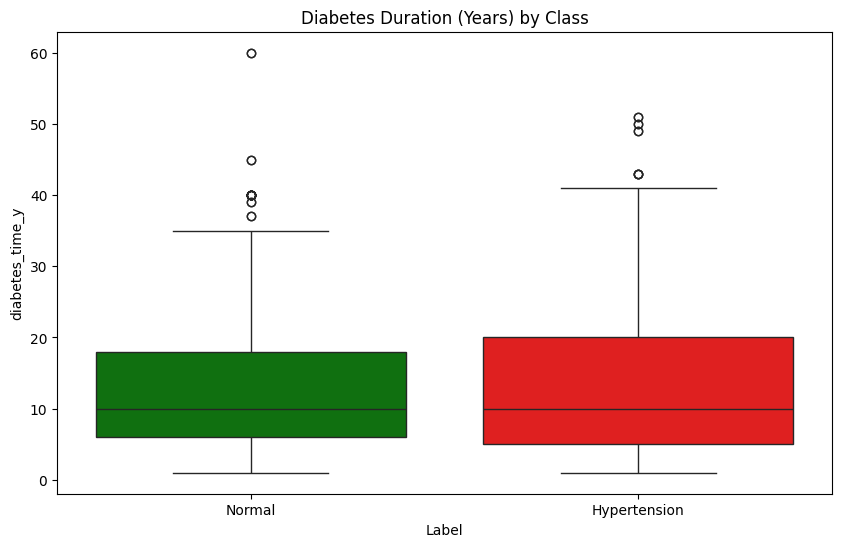

Diabetes Duration Comparison: p-value = 7.0383e-01

--- 3.4 Insulin Dependency Analysis ---


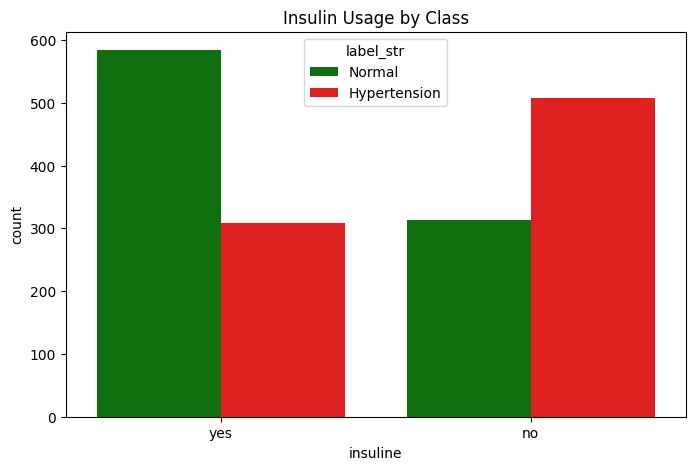

Insulin Usage Comparison: p-value = 4.2948e-29


In [50]:
# 3.3 Diabetes Duration Analysis
print("\n--- 3.3 Diabetes Duration Analysis ---")
plt.figure(figsize=(10, 6))
# Use label_str for plotting
sns.boxplot(x='label_str', y='diabetes_time_y', data=df, palette={'Normal':'green', 'Hypertension':'red'})
plt.title('Diabetes Duration (Years) by Class')
plt.xlabel('Label')
plt.show()

time_normal = df[df['label']==0]['diabetes_time_y'].dropna()
time_hyper = df[df['label']==1]['diabetes_time_y'].dropna()

if len(time_normal) > 0 and len(time_hyper) > 0:
    stat, p_val = mannwhitneyu(time_normal, time_hyper)
    print(f"Diabetes Duration Comparison: p-value = {p_val:.4e}")
else:
    print("Insufficient data for Diabetes Duration comparison.")


# 3.4 Insulin Dependency Analysis
print("\n--- 3.4 Insulin Dependency Analysis ---")
plt.figure(figsize=(8, 5))
# Use label_str for plotting
sns.countplot(x='insuline', hue='label_str', data=df, palette={'Normal':'green', 'Hypertension':'red'})
plt.title('Insulin Usage by Class')
plt.show()

ct_ins = pd.crosstab(df['insuline'], df['label'])
if not ct_ins.empty:
    chi2, p_val, dof, expected = chi2_contingency(ct_ins)
    print(f"Insulin Usage Comparison: p-value = {p_val:.4e}")

# Stage 4

In [52]:
# Stage 4: Advanced Imaging Analytics (UMAP)
# ----------------------------------------------------------------
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing import image
import umap.umap_ as umap
from sklearn.preprocessing import StandardScaler

# 1. Setup Feature Extractor (ResNet50 without top classification layer)
print("--- 1. Loading Feature Extractor (ResNet50) ---")
model = ResNet50(weights='imagenet', include_top=False, pooling='avg')

def extract_features(img_path):
    try:
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = preprocess_input(x)
        features = model.predict(x, verbose=0)
        return features.flatten()
    except Exception as e:
        return None



--- 1. Loading Feature Extractor (ResNet50) ---
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [53]:
# 2. Process a Sample
SAMPLE_SIZE = 16000
print(f"--- 2. Extracting Features from {SAMPLE_SIZE} images ---")

# Ensure we pick valid files only
valid_df = df[df['filepath'].apply(os.path.exists)].sample(SAMPLE_SIZE, random_state=42).copy()

features_list = []
valid_indices = []

for idx, row in tqdm(valid_df.iterrows(), total=len(valid_df)):
    feat = extract_features(row['filepath'])
    if feat is not None:
        features_list.append(feat)
        valid_indices.append(idx)

X = np.array(features_list)
print(f"Feature Matrix Shape: {X.shape}")



--- 2. Extracting Features from 16000 images ---


100%|██████████| 16000/16000 [1:16:30<00:00,  3.49it/s]


Feature Matrix Shape: (16000, 2048)


In [54]:
# 3. UMAP Reduction
print("--- 3. Running UMAP Reduction ---")
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
embedding = reducer.fit_transform(StandardScaler().fit_transform(X))

valid_df = valid_df.loc[valid_indices]
valid_df['umap_x'] = embedding[:, 0]
valid_df['umap_y'] = embedding[:, 1]



--- 3. Running UMAP Reduction ---


c:\Users\msii\AppData\Local\Programs\Python\Python311\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


--- 4. Visualizing Embeddings ---


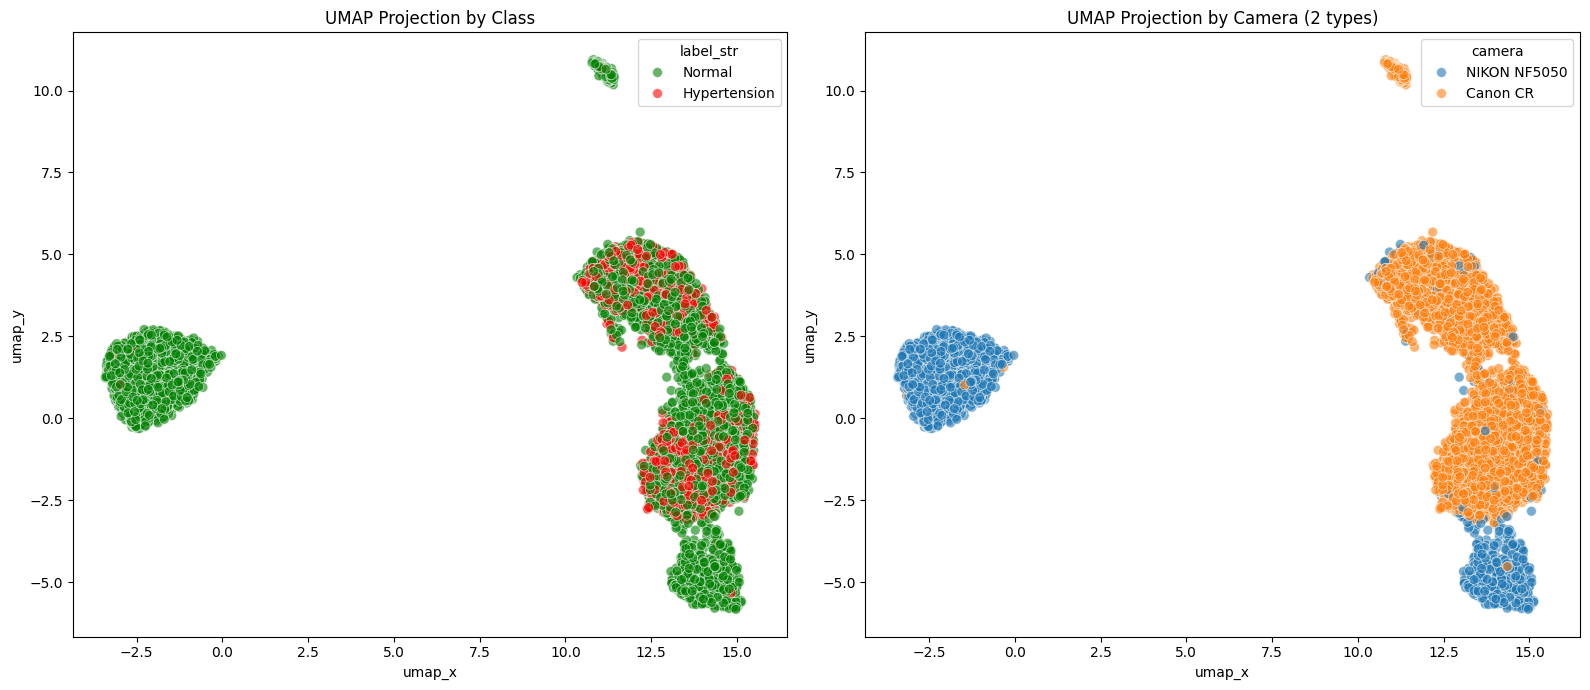

Interpretation:
- Distinct clusters by Camera indicate 'Batch Effects' (Model learns camera, not disease).
- Distinct clusters by Label indicate easy separability (or possible leakage).
- Overlapping clusters mean the problem is hard/non-trivial.


In [55]:
# 4. Visualization
print("--- 4. Visualizing Embeddings ---")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: by Label
sns.scatterplot(
    x='umap_x', y='umap_y', hue='label_str', 
    data=valid_df, palette={'Normal':'green', 'Hypertension':'red'},
    alpha=0.6, s=50, ax=axes[0]
)
axes[0].set_title('UMAP Projection by Class')

# Plot 2: by Camera (if available and not just one type)
# We check how many unique cameras exist first
unique_cameras = valid_df['camera'].nunique()
if unique_cameras > 1:
    sns.scatterplot(
        x='umap_x', y='umap_y', hue='camera', 
        data=valid_df, 
        alpha=0.6, s=50, ax=axes[1]
    )
    axes[1].set_title(f'UMAP Projection by Camera ({unique_cameras} types)')
else:
    # Fallback if only 1 camera: Color by Age
    points = axes[1].scatter(valid_df['umap_x'], valid_df['umap_y'], c=valid_df['patient_age'], cmap='viridis', alpha=0.6)
    plt.colorbar(points, ax=axes[1], label='Age')
    axes[1].set_title('UMAP Projection by Patient Age')

plt.tight_layout()
plt.show()

print("Interpretation:")
print("- Distinct clusters by Camera indicate 'Batch Effects' (Model learns camera, not disease).")
print("- Distinct clusters by Label indicate easy separability (or possible leakage).")
print("- Overlapping clusters mean the problem is hard/non-trivial.")